In [1]:
!pip install -q transformers peft trl accelerate datasets bitsandbytes sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 22.5 MB/s eta 0:00:00


In [2]:
!pip uninstall -y torchao -q

In [3]:
import torch
import time
import textwrap
import numpy as np
from google.colab import drive
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel

# 1. Mount Drive
drive.mount('/content/drive')

# 2. Load Base Model and Tokenizer
model_name = "Qwen/Qwen2.5-0.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(model_name)
base_model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float16, device_map="auto")

# 3. Load Adapters into the Base Model
# Load Programming as the primary PEFT model, then attach Finance as a secondary adapter
model = PeftModel.from_pretrained(base_model, "drive/MyDrive/LoRA-Adapters/adapters/programming_adapter", adapter_name="programming")
model.load_adapter("drive/MyDrive/LoRA-Adapters/adapters/finance_adapter", adapter_name="finance")

print("Model and adapters loaded successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model and adapters loaded successfully!


In [4]:
from sentence_transformers import SentenceTransformer
from datasets import load_dataset

embedder = SentenceTransformer('all-MiniLM-L6-v2')

# Load the datasets to rebuild the centroids
prog_data = load_dataset("json", data_files="drive/MyDrive/LoRA-Adapters/data/programming.jsonl", split="train")
fin_data = load_dataset("json", data_files="drive/MyDrive/LoRA-Adapters/data/finance.jsonl", split="train")

# Calculate centroids
prog_emb = embedder.encode([ex['instruction'] for ex in prog_data.select(range(100))])
fin_emb = embedder.encode([ex['instruction'] for ex in fin_data.select(range(100))])

centroids = {
    "programming": np.mean(prog_emb, axis=0),
    "finance": np.mean(fin_emb, axis=0),
}

def route_query(query, temperature=0.1):
    query_emb = embedder.encode(query)
    sims = {}
    for domain, centroid in centroids.items():
        sim = np.dot(query_emb, centroid) / (np.linalg.norm(query_emb) * np.linalg.norm(centroid))
        sims[domain] = sim

    sim_values = np.array(list(sims.values())) / temperature
    exp_sims = np.exp(sim_values - np.max(sim_values))
    weights = exp_sims / exp_sims.sum()
    return dict(zip(sims.keys(), weights))

print("Router and centroids initialized!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Router and centroids initialized!


In [5]:
def run_evaluation(query, static_fallback="programming"):
    print(f"\n{'='*70}\nQUERY: {query}\n{'='*70}")

    prompt = f"### Instruction:\n{query}\n\n### Response:\n"
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    torch.cuda.reset_peak_memory_stats()

    # --- 1. ROUTER OVERHEAD ---
    t0 = time.perf_counter()
    weights = route_query(query)
    router_calc_latency = (time.perf_counter() - t0) * 1000

    print(f"\n[ROUTER DECISION]")
    print(f"Calculated Weights: {weights}")
    print(f"Router Math Latency: {router_calc_latency:.2f} ms")

    # --- 2. STATIC ADAPTER (Baseline comparison) ---
    model.set_adapter(static_fallback)
    t1 = time.perf_counter()
    with torch.no_grad():
        static_out = model.generate(**inputs, max_new_tokens=100, do_sample=False)
    static_gen_latency = (time.perf_counter() - t1) * 1000
    static_text = tokenizer.decode(static_out[0], skip_special_tokens=True).split("### Response:\n")[-1]

    # --- 3. DYNAMIC ROUTER BLEND ---
    model.add_weighted_adapter(
        adapters=["programming", "finance"],
        weights=[weights["programming"], weights["finance"]],
        adapter_name="eval_blend",
        combination_type="linear"
    )
    model.set_adapter("eval_blend")

    t2 = time.perf_counter()
    with torch.no_grad():
        router_out = model.generate(**inputs, max_new_tokens=100, do_sample=False)
    router_gen_latency = (time.perf_counter() - t2) * 1000
    router_text = tokenizer.decode(router_out[0], skip_special_tokens=True).split("### Response:\n")[-1]

    peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 2)
    model.delete_adapter("eval_blend")

    # --- RESULTS ---
    print(f"\n[SYSTEM METRICS]")
    print(f"Static Generation Latency: {static_gen_latency:.2f} ms")
    print(f"Router Generation Latency: {router_gen_latency:.2f} ms")
    print(f"Total VRAM Allocated:      {peak_vram:.2f} MB")

    print(f"\n[STATIC RESPONSE ({static_fallback.upper()})]\n{textwrap.fill(static_text, 70)}")
    print(f"\n[ROUTER RESPONSE (BLENDED)]\n{textwrap.fill(router_text, 70)}\n")

In [6]:
# Pure Programming Test
run_evaluation("What is the time complexity of a binary search tree?", static_fallback="finance")

# Pure Finance Test
run_evaluation("What happens to bond prices when interest rates rise?", static_fallback="programming")

# Mixed-Domain Test (The critical one)
run_evaluation("Write a Python script using pandas to calculate compound interest for a stock portfolio.", static_fallback="programming")


QUERY: What is the time complexity of a binary search tree?

[ROUTER DECISION]
Calculated Weights: {'programming': np.float32(0.56589586), 'finance': np.float32(0.43410417)}
Router Math Latency: 35.93 ms


/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1683: UserWarning: Adapter eval_blend was active which is now deleted. Setting active adapter to finance.
  warnings.warn(



[SYSTEM METRICS]
Static Generation Latency: 3830.00 ms
Router Generation Latency: 3196.85 ms
Total VRAM Allocated:      1046.86 MB

[STATIC RESPONSE (FINANCE)]
The time complexity for a binary search tree is O(log n).

[ROUTER RESPONSE (BLENDED)]
The time complexity for a binary search tree (BST) is O(log n), where
'n' represents the number of nodes in the tree.


QUERY: What happens to bond prices when interest rates rise?

[ROUTER DECISION]
Calculated Weights: {'programming': np.float32(0.07569697), 'finance': np.float32(0.924303)}
Router Math Latency: 13.08 ms

[SYSTEM METRICS]
Static Generation Latency: 10736.03 ms
Router Generation Latency: 1228.71 ms
Total VRAM Allocated:      1046.65 MB

[STATIC RESPONSE (PROGRAMMING)]
When interest rates rise, the price of bonds typically falls. This is
because higher interest rates make borrowing more expensive, which
reduces the amount of money available for investment and thus lowers
the value of bonds.  For example, if the market rate of i

In [7]:
import json
import time
import torch
import textwrap

# 1. Update the function so it returns the data for the JSON
def run_evaluation(query, static_fallback="programming"):
    print(f"\n{'='*70}\nQUERY: {query}\n{'='*70}")

    prompt = f"### Instruction:\n{query}\n\n### Response:\n"
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    torch.cuda.reset_peak_memory_stats()

    # Router Math
    t0 = time.perf_counter()
    weights = route_query(query)
    router_calc_ms = (time.perf_counter() - t0) * 1000

    # Static Adapter Generation
    model.set_adapter(static_fallback)
    t1 = time.perf_counter()
    with torch.no_grad():
        static_out = model.generate(**inputs, max_new_tokens=100, do_sample=False)
    static_gen_ms = (time.perf_counter() - t1) * 1000
    static_text = tokenizer.decode(static_out[0], skip_special_tokens=True).split("### Response:\n")[-1].strip()

    # Dynamic Router Blend Generation
    model.add_weighted_adapter(
        adapters=["programming", "finance"],
        weights=[weights["programming"], weights["finance"]],
        adapter_name="eval_blend",
        combination_type="linear"
    )
    model.set_adapter("eval_blend")
    t2 = time.perf_counter()
    with torch.no_grad():
        router_out = model.generate(**inputs, max_new_tokens=100, do_sample=False)
    router_gen_ms = (time.perf_counter() - t2) * 1000
    router_text = tokenizer.decode(router_out[0], skip_special_tokens=True).split("### Response:\n")[-1].strip()

    peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 2)
    model.delete_adapter("eval_blend")

    # Print live progress
    print(f"Weights: {weights}")
    print(f"Router Gen Latency: {router_gen_ms:.2f} ms | VRAM: {peak_vram:.2f} MB")
    print(f"Blended Response:\n{textwrap.fill(router_text, 70)}")

    # Return the dictionary so we can save it to JSON
    return {
        "query": query,
        "weights": {k: float(v) for k, v in weights.items()},
        "router_math_ms": round(router_calc_ms, 2),
        "static_gen_ms": round(static_gen_ms, 2),
        "router_gen_ms": round(router_gen_ms, 2),
        "peak_vram_mb": round(peak_vram, 2),
        "static_response": static_text,
        "router_response": router_text
    }

# 2. Call the function directly for the 10 queries
queries = [
    # EASY
    {"q": "What is a mutual fund and how does it pool money?", "static": "programming"},
    {"q": "How do you write a standard for loop in Python?", "static": "finance"},
    {"q": "What does compound interest mean for a long-term investment?", "static": "programming"},
    {"q": "What is the exact difference between a list and a tuple in Python?", "static": "finance"},
    {"q": "Write a Python script using pandas to track a stock portfolio.", "static": "programming"},
    # HARD
    {"q": "What is a recursive function, and how does the call stack manage its memory?", "static": "finance"},
    {"q": "What is the mechanism behind algorithmic high-frequency trading latency?", "static": "programming"},
    {"q": "If a central bank decreases interest rates, why exactly do bond prices go up?", "static": "programming"},
    {"q": "Write a Python script that calculates the 30-day moving average of a stock.", "static": "finance"},
    {"q": "What is the most efficient way to manage a queue in a banking system?", "static": "programming"}
]

# 3. Loop, collect, and save to JSON
results = []
for item in queries:
    data = run_evaluation(item["q"], static_fallback=item["static"])
    results.append(data)

with open("drive/MyDrive/LoRA-Adapters/eval/midsem_10_queries.json", "w") as f:
    json.dump(results, f, indent=4)

print("\n✅ All 10 queries complete! JSON successfully saved.")


QUERY: What is a mutual fund and how does it pool money?
Weights: {'programming': np.float32(0.017292654), 'finance': np.float32(0.9827073)}
Router Gen Latency: 896.37 ms | VRAM: 1046.77 MB
Blended Response:
A mutual fund pools the funds of many investors to buy stocks, bonds,
or other securities.

QUERY: How do you write a standard for loop in Python?
Weights: {'programming': np.float32(0.9877765), 'finance': np.float32(0.012223461)}
Router Gen Latency: 4838.12 ms | VRAM: 1048.14 MB
Blended Response:
To write a standard for loop in Python, you can use the `for`
statement. Here's an example:  ```python for i in range(10):
print(i) ```  In this example, the `range(10)` function generates a
sequence of numbers from 0 to 9 (inclusive). The `for` statement then
iterates over each number in this sequence and prints it.  You can
also specify a step value when using the `range()` function. For

QUERY: What does compound interest mean for a long-term investment?
Weights: {'programming': np.fl

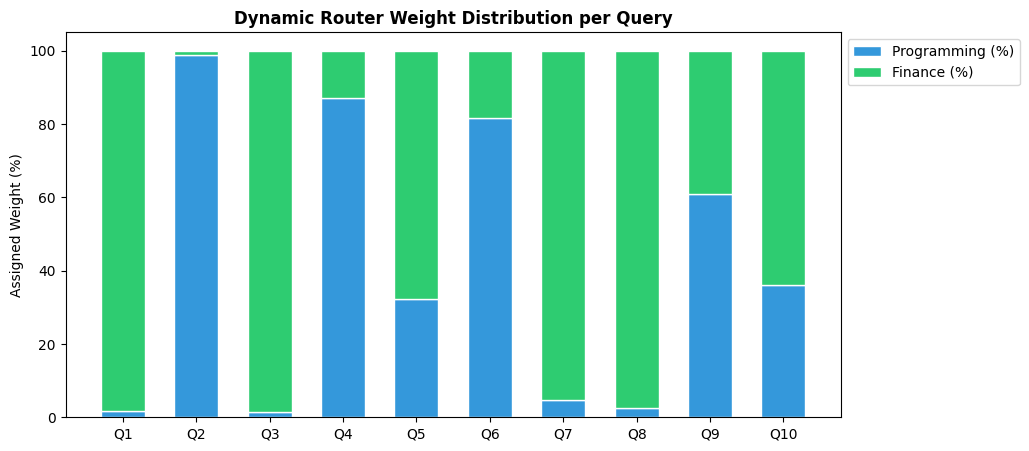

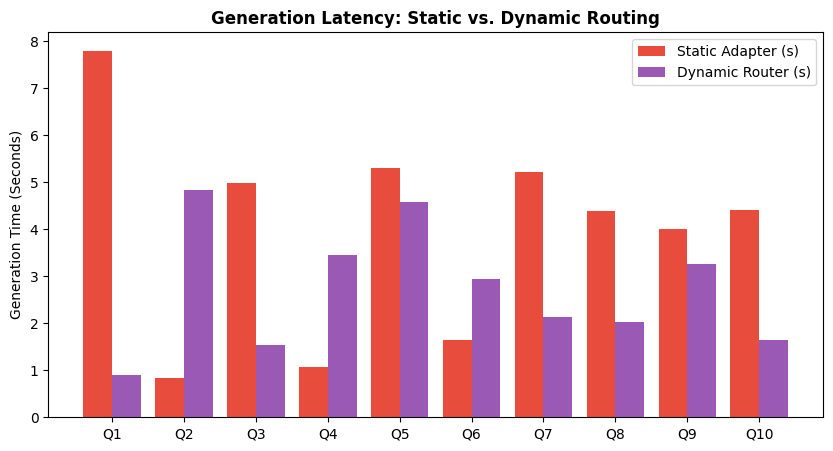

In [8]:
import json
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Load your results
with open("drive/MyDrive/LoRA-Adapters/eval/midsem_10_queries.json", "r") as f:
    results = json.load(f)

queries = [f"Q{i+1}" for i in range(len(results))]
prog_weights = [r["weights"]["programming"] * 100 for r in results]
fin_weights = [r["weights"]["finance"] * 100 for r in results]

# 1. GRAPH: Routing Weight Distribution
plt.figure(figsize=(10, 5))
barWidth = 0.6
plt.bar(queries, prog_weights, color='#3498db', edgecolor='white', width=barWidth, label='Programming (%)')
plt.bar(queries, fin_weights, bottom=prog_weights, color='#2ecc71', edgecolor='white', width=barWidth, label='Finance (%)')
plt.title("Dynamic Router Weight Distribution per Query", fontweight='bold')
plt.ylabel("Assigned Weight (%)")
plt.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.savefig("drive/MyDrive/LoRA-Adapters/eval/weight_distribution.png", bbox_inches='tight')
plt.show()

# 2. GRAPH: Latency Overhead (Static vs Blended)
static_latency = [r["static_gen_ms"] / 1000 for r in results]
router_latency = [r["router_gen_ms"] / 1000 for r in results]

plt.figure(figsize=(10, 5))
x = np.arange(len(queries))
plt.bar(x - 0.2, static_latency, 0.4, label='Static Adapter (s)', color='#e74c3c')
plt.bar(x + 0.2, router_latency, 0.4, label='Dynamic Router (s)', color='#9b59b6')
plt.xticks(x, queries)
plt.ylabel("Generation Time (Seconds)")
plt.title("Generation Latency: Static vs. Dynamic Routing", fontweight='bold')
plt.legend()
plt.savefig("drive/MyDrive/LoRA-Adapters/eval/latency_comparison.png")
plt.show()